# Held-out HMM predictive scores

Change `RESULT_DIR` below to inspect another run. No models are fitted here.

- Higher log predictive density is better. Compare models within the same PCA setting and on identical dates.
- Each test block freezes model parameters; state probabilities still update sequentially.
- Scores describe the transformed feature vector, not trading profitability.
- PCA dimensionality and scaling can change between folds: absolute scores across folds are not on a fixed original-data scale. Paired differences within each fold cancel the shared preprocessing effect.
- A training improvement with a held-out decline supports overfitting; a plateau alone supports parsimony, not proof of noise fitting.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RESULT_DIR = ROOT / "notebooks/sp500/results/heldout_gmm_2004_2025"
BASELINE_M = 3

daily = pd.read_csv(RESULT_DIR / "daily_scores.csv", parse_dates=["date", "train_end"])
folds = pd.read_csv(RESULT_DIR / "fold_scores.csv", parse_dates=["train_end", "test_start", "test_end"])
assert not daily.empty
assert not daily.duplicated(["date", "spec"]).any()
assert not folds.duplicated(["fold", "spec"]).any()
assert np.isfinite(daily["log_predictive"]).all()
assert (daily["train_end"] < daily["date"]).all()
assert (folds["train_end"] < folds["test_start"]).all()
settings_path = RESULT_DIR / "settings.json"
if settings_path.exists():
    settings = json.loads(settings_path.read_text())
    display(pd.Series(settings, name="setting").to_frame())
    print("Requested end:", settings["end"])
print("Available scores:", daily.date.min().date(), "to", daily.date.max().date())
print("Completed blocks:", folds.fold.nunique(), "branches:", daily.spec.nunique())
print("If the runner is still active, rerun this notebook to load later blocks.")
display(daily.groupby(["pca", "spec"]).agg(days=("date", "size"), first=("date", "min"), last=("date", "max")))


/Users/yushe/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/82/mbpcsh414ss_92y_xkg174n80000gn/T/matplotlib-mczws_2q because there was an issue with the default path (/Users/yushe/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Matplotlib is building the font cache; this may take a moment.


,setting
version,1
start,2004-01-02 00:00:00
end,2025-12-30 00:00:00
years,10
seed,0
max_iter,100
test_days,63
models,"[gmm2_pca, gmm3_pca, gmm4_pca, gmm5_pca]"
windows,"[5, 10, 60]"
half_lives,"[5, 10, 60]"


Requested end: 2025-12-30 00:00:00
Available scores: 2004-01-02 to 2025-12-30
Completed blocks: 88 branches: 4
If the runner is still active, rerun this notebook to load later blocks.


days      first       last
pca  spec                                
True gmm2_pca  5534 2004-01-02 2025-12-30
     gmm3_pca  5534 2004-01-02 2025-12-30
     gmm4_pca  5534 2004-01-02 2025-12-30
     gmm5_pca  5534 2004-01-02 2025-12-30

In [2]:
# Require identical dates and feature spaces within each PCA setting.
wide_scores = {}
for use_pca, group in daily.groupby("pca"):
    wide = group.pivot(index="date", columns="spec", values="log_predictive").sort_index()
    if wide.isna().any().any():
        raise ValueError("Branches have different dates; rerun after a complete block is saved")
    if group.groupby("date")["n_features"].nunique().gt(1).any():
        raise ValueError("Models use different feature dimensions")
    wide_scores[use_pca] = wide

summary = daily.groupby(["pca", "spec"]).agg(
    observations=("log_predictive", "size"),
    mean_test_log_score=("log_predictive", "mean"),
    total_test_log_score=("log_predictive", "sum"),
)
fit_diagnostics = folds.groupby(["pca", "spec"]).agg(
    folds=("fold", "size"), convergence_rate=("converged", "mean"),
    mean_iterations=("iterations", "mean"),
)
display(summary.join(fit_diagnostics).round(4))


observations  mean_test_log_score  total_test_log_score  folds  \
pca  spec                                                                       
True gmm2_pca          5534              -6.9946           -38708.1939     88   
     gmm3_pca          5534              -6.2696           -34696.1738     88   
     gmm4_pca          5534              -6.3809           -35311.6952     88   
     gmm5_pca          5534              -6.2598           -34641.5660     88   

               convergence_rate  mean_iterations  
pca  spec                                         
True gmm2_pca            0.9318          53.9432  
     gmm3_pca            0.9545          55.7727  
     gmm4_pca            0.9091          63.8068  
     gmm5_pca            0.8750          66.9432

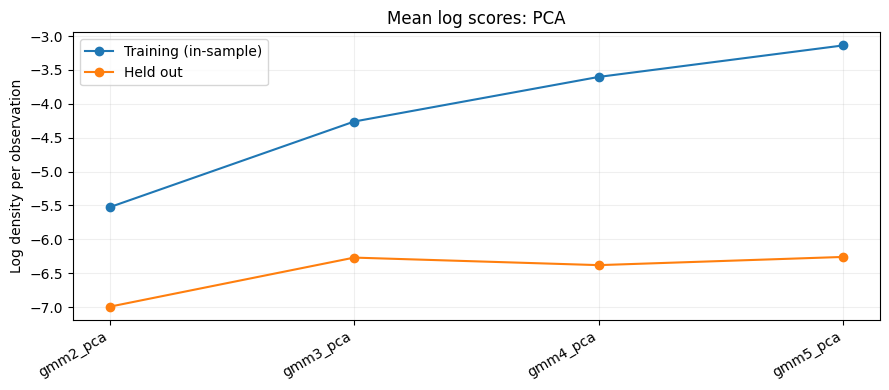

In [3]:
# Weight fold-level means by their observation counts.
for use_pca, group in folds.groupby("pca"):
    rows = []
    for spec, branch in group.groupby("spec"):
        rows.append({
            "spec": spec, "M": branch.gmm_components.iloc[0],
            "train": np.average(branch.train_mean_log_score, weights=branch.training_days),
            "test": np.average(branch.test_mean_log_score, weights=branch.test_days),
        })
    table = pd.DataFrame(rows).sort_values(["M", "spec"])
    fig, ax = plt.subplots(figsize=(9, 4))
    x = np.arange(len(table))
    ax.plot(x, table.train, "o-", label="Training (in-sample)")
    ax.plot(x, table.test, "o-", label="Held out")
    ax.set_xticks(x, table.spec, rotation=30, ha="right")
    ax.set(title=f"Mean log scores: {'PCA' if use_pca else 'no PCA'}", ylabel="Log density per observation")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


## Paired comparisons against M = 3

Positive differences favor the alternative; negative differences favor M = 3. Cumulative differences reveal whether a result is sustained or driven by a short period. Block win fractions are descriptive, not significance tests. First and last blocks may differ in length.


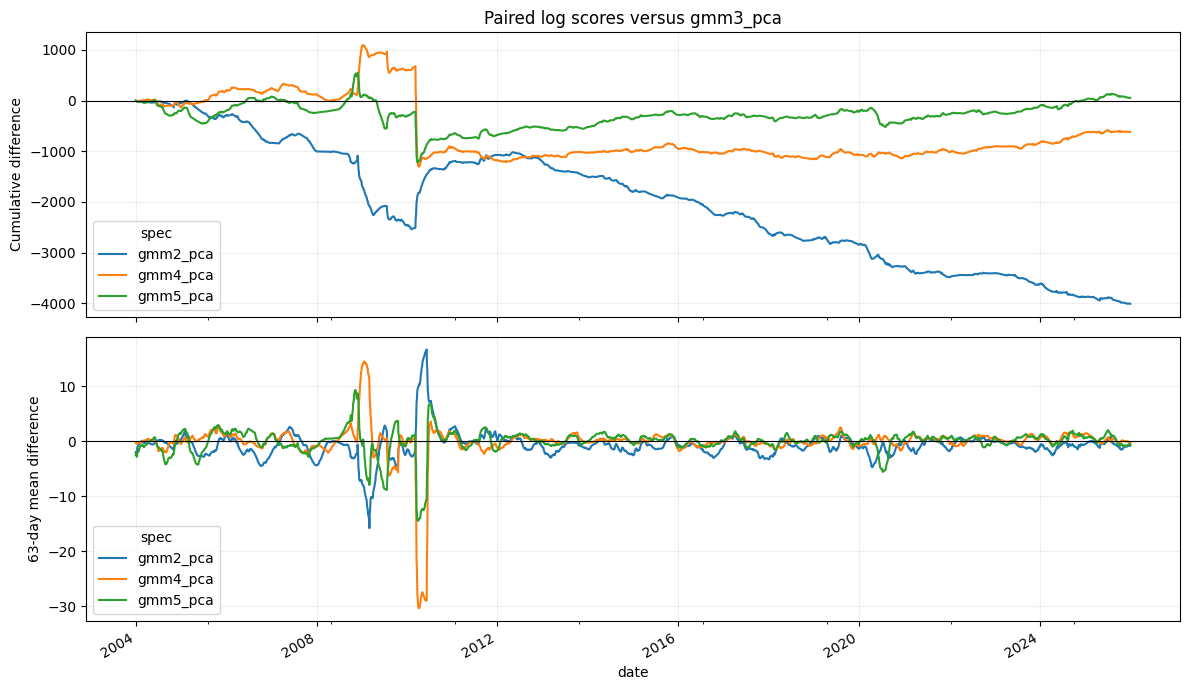

baseline  mean_daily_difference  total_difference  \
pca  spec                                                          
True gmm2_pca  gmm3_pca                -0.7250        -4012.0201   
     gmm4_pca  gmm3_pca                -0.1112         -615.5214   
     gmm5_pca  gmm3_pca                 0.0099           54.6078   

               fraction_blocks_better  blocks  
pca  spec                                      
True gmm2_pca                  0.3068      88  
     gmm4_pca                  0.5455      88  
     gmm5_pca                  0.6136      88

In [4]:
paired_rows = []
for use_pca, wide in wide_scores.items():
    baseline = f"gmm{BASELINE_M}_{'pca' if use_pca else 'no_pca'}"
    if baseline not in wide:
        print("Skipping baseline comparison; missing", baseline)
        continue
    differences = wide.subtract(wide[baseline], axis=0).drop(columns=baseline)
    if differences.empty:
        continue
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    differences.cumsum().plot(ax=axes[0])
    differences.rolling(63, min_periods=1).mean().plot(ax=axes[1])
    axes[0].set(title=f"Paired log scores versus {baseline}", ylabel="Cumulative difference")
    axes[1].set(ylabel="63-day mean difference")
    for ax in axes:
        ax.axhline(0, color="black", linewidth=0.8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    block_table = folds.loc[folds.pca == use_pca].pivot(index="fold", columns="spec", values="test_mean_log_score")
    for spec in differences:
        block_difference = block_table[spec] - block_table[baseline]
        paired_rows.append({
            "pca": use_pca, "spec": spec, "baseline": baseline,
            "mean_daily_difference": differences[spec].mean(),
            "total_difference": differences[spec].sum(),
            "fraction_blocks_better": (block_difference > 0).mean(),
            "blocks": len(block_difference),
        })
if paired_rows:
    display(pd.DataFrame(paired_rows).set_index(["pca", "spec"]).round(4))


In [5]:
# Inspect individual blocks, dimension changes, and optimization failures.
display(folds[["fold", "spec", "train_end", "test_start", "test_end", "training_days",
               "test_days", "n_features", "train_mean_log_score", "test_mean_log_score",
               "converged", "iterations"]].round(4))
failures = folds.loc[~folds["converged"]]
print("Non-converged fits:", len(failures))
if not failures.empty:
    display(failures[["fold", "spec", "iterations", "test_mean_log_score"]])


,fold,spec,train_end,test_start,test_end,training_days,test_days,n_features,train_mean_log_score,test_mean_log_score,converged,iterations
0,0,gmm2_pca,2003-12-31,2004-01-02,2004-04-01,2519,63,11,-5.9568,-5.5642,True,57
1,0,gmm3_pca,2003-12-31,2004-01-02,2004-04-01,2519,63,11,-6.0981,-5.1570,True,26
2,0,gmm4_pca,2003-12-31,2004-01-02,2004-04-01,2519,63,11,-4.9038,-4.8275,True,44
3,0,gmm5_pca,2003-12-31,2004-01-02,2004-04-01,2519,63,11,-3.4919,-5.7448,True,61
4,1,gmm2_pca,2004-04-01,2004-04-02,2004-07-02,2582,63,11,-5.8865,-3.7608,True,75
...,...,...,...,...,...,...,...,...,...,...,...,...
347,86,gmm5_pca,2025-07-16,2025-07-17,2025-10-14,7937,63,11,-2.7089,-6.6818,True,60
348,87,gmm2_pca,2025-10-14,2025-10-15,2025-12-30,8000,53,11,-4.4110,-1.9082,True,64
349,87,gmm3_pca,2025-10-14,2025-10-15,2025-12-30,8000,53,11,-3.4316,-1.4437,True,45
350,87,gmm4_pca,2025-10-14,2025-10-15,2025-12-30,8000,53,11,-3.2520,-1.4452,True,38


Non-converged fits: 29


,fold,spec,iterations,test_mean_log_score
24,6,gmm2_pca,100,-4.679537
31,7,gmm5_pca,100,-3.842304
64,16,gmm2_pca,100,-1.463448
67,16,gmm5_pca,100,-0.926923
68,17,gmm2_pca,100,-1.917078
101,25,gmm3_pca,100,-18.151252
104,26,gmm2_pca,100,-8.502844
127,31,gmm5_pca,100,-8.932738
146,36,gmm4_pca,100,-3.995825
151,37,gmm5_pca,100,-2.507223
